# PaySim : analyse exploratoire guidée

**Lot 4.0, étape 1.** Ce notebook lit le CSV PaySim brut depuis la racine du dépôt. Il ne modifie pas les données et n'entraîne aucun modèle. `isFraud` est consulté uniquement pour l'analyse hors ligne. Les autres labels ne sont pas des variables prédictives.

Les deux premières figures montrent le déséquilibre des classes et l'étendue des montants. Les conclusions sur les montants selon le label, les types, le temps et les soldes attendent la discussion avec l'utilisateur.


In [1]:
from pathlib import Path
from hashlib import sha256
from html import escape
import math
import polars as pl

CSV = Path("data/raw/PS_20174392719_1491204439457_log.csv")
FIGURES = Path("docs/figures")
EXPECTED_SHA256 = "16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b"
if not CSV.is_file():
    raise FileNotFoundError(f"CSV absent : {CSV}. Voir README.md pour le téléchargement.")
with CSV.open("rb") as source:
    digest = sha256()
    for block in iter(lambda: source.read(1024 * 1024), b""):
        digest.update(block)
assert digest.hexdigest() == EXPECTED_SHA256, "Empreinte du CSV différente de l'audit"

frame = pl.scan_csv(CSV).select("amount", "isFraud")
summary = frame.select(
    pl.len().alias("total"),
    (pl.col("isFraud") == 0).sum().alias("normal"),
    (pl.col("isFraud") == 1).sum().alias("fraud"),
    (~pl.col("isFraud").is_in([0, 1])).sum().alias("other_label"),
    (pl.col("amount") == 0).sum().alias("zeros"),
    (pl.col("amount") < 0).sum().alias("negatives"),
    pl.col("amount").min().alias("minimum"),
    pl.col("amount").max().alias("maximum"),
    pl.col("amount").median().alias("median"),
    pl.col("amount").quantile(0.90).alias("p90"),
    pl.col("amount").quantile(0.99).alias("p99"),
).collect().row(0, named=True)
assert summary["total"] == 6_362_620
assert summary["normal"] + summary["fraud"] == summary["total"]
assert summary["other_label"] == 0 and summary["negatives"] == 0

# Tranches [10**e, 10**(e+1)) pour les montants strictement positifs.
bins = (
    frame.filter(pl.col("amount") > 0)
    .with_columns(pl.col("amount").log10().floor().cast(pl.Int32).alias("exponent"))
    .group_by("exponent").agg(pl.len().alias("count"))
    .sort("exponent").collect()
)
assert sum(bins["count"].to_list()) + summary["zeros"] == summary["total"]
assert bins["exponent"].to_list() == list(range(-2, 8))
print({key: summary[key] for key in ("total", "normal", "fraud", "zeros", "minimum", "maximum", "median", "p90", "p99")})
print(bins)


In [2]:
def svg_text(x, y, value, *, size=16, fill="#183047", anchor="start", weight="normal"):
    return (f'<text x="{x}" y="{y}" font-family="Arial, sans-serif" '
            f'font-size="{size}" fill="{fill}" text-anchor="{anchor}" '
            f'font-weight="{weight}">{escape(str(value))}</text>')


def show_svg(svg):
    try:
        from IPython.display import SVG, display
    except ModuleNotFoundError:
        return
    display(SVG(svg))


def save_svg(name, svg):
    FIGURES.mkdir(parents=True, exist_ok=True)
    path = FIGURES / name
    path.write_text(svg, encoding="utf-8")
    return svg


def format_int(value):
    return f"{value:,}".replace(",", " ")


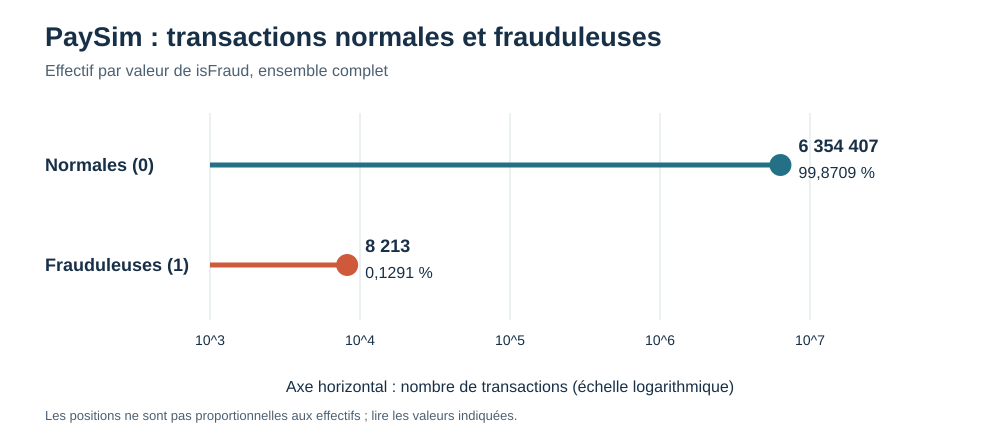

In [3]:
width, height = 1000, 440
left, right = 210, 810
x = lambda value: left + (math.log10(value) - 3) / 4 * (right - left)
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(45, 46, "PaySim : transactions normales et frauduleuses", size=27, weight="bold"),
         svg_text(45, 76, "Effectif par valeur de isFraud, ensemble complet", size=16, fill="#4b6072")]
for power in range(3, 8):
    xpos = x(10 ** power)
    parts += [f'<line x1="{xpos}" y1="113" x2="{xpos}" y2="320" stroke="#d8e1e8"/>',
              svg_text(xpos, 345, f"10^{power}", size=14, anchor="middle")]
for y, name, value, color in [(165, "Normales (0)", summary["normal"], "#237087"),
                               (265, "Frauduleuses (1)", summary["fraud"], "#ce593b")]:
    xpos = x(value)
    parts += [svg_text(45, y + 6, name, size=18, weight="bold"),
              f'<line x1="{left}" y1="{y}" x2="{xpos}" y2="{y}" stroke="{color}" stroke-width="5"/>',
              f'<circle cx="{xpos}" cy="{y}" r="11" fill="{color}"/>',
              svg_text(min(xpos + 18, 845), y - 13, f"{format_int(value)}", size=18, weight="bold"),
              svg_text(min(xpos + 18, 845), y + 13, f"{value / summary['total'] * 100:.4f} %".replace(".", ","), size=16)]
parts += [svg_text(510, 392, "Axe horizontal : nombre de transactions (échelle logarithmique)", size=16, anchor="middle"),
          svg_text(45, 420, "Les positions ne sont pas proportionnelles aux effectifs ; lire les valeurs indiquées.", size=13, fill="#4b6072"),
          '</svg>']
class_svg = save_svg("eda_classes.svg", "\n".join(parts))
show_svg(class_svg)


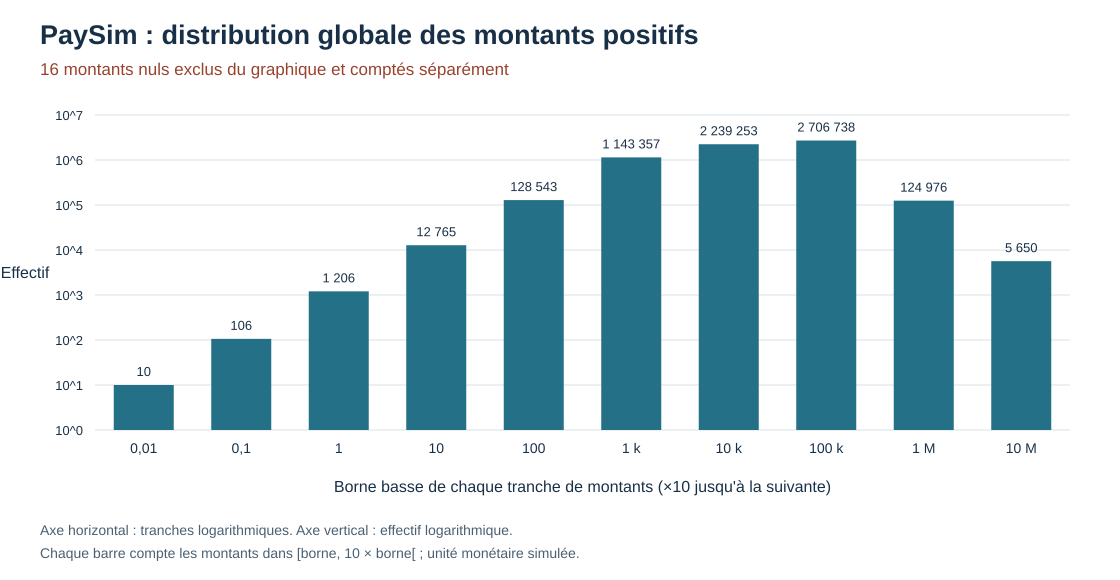

In [4]:
width, height = 1120, 580
left, right, top, bottom = 95, 1070, 115, 430
counts = bins["count"].to_list()
exponents = bins["exponent"].to_list()
max_power = 7
bar_width = (right - left) / len(counts)
y = lambda count: bottom - math.log10(count) / max_power * (bottom - top)
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 44, "PaySim : distribution globale des montants positifs", size=27, weight="bold"),
         svg_text(40, 75, f"{format_int(summary['zeros'])} montants nuls exclus du graphique et comptés séparément", size=17, fill="#9a422e")]
for power in range(0, max_power + 1):
    value = 10 ** power
    ypos = y(value)
    parts += [f'<line x1="{left}" y1="{ypos}" x2="{right}" y2="{ypos}" stroke="#d8e1e8"/>',
              svg_text(left - 12, ypos + 5, f"10^{power}", size=13, anchor="end")]
labels = ["0,01", "0,1", "1", "10", "100", "1 k", "10 k", "100 k", "1 M", "10 M"]
for i, (exp, count) in enumerate(zip(exponents, counts)):
    center = left + (i + 0.5) * bar_width
    ypos = y(count)
    parts += [f'<rect x="{center - 30}" y="{ypos}" width="60" height="{bottom - ypos}" fill="#237087"/>',
              svg_text(center, max(ypos - 9, 103), format_int(count), size=13, anchor="middle"),
              svg_text(center, 453, labels[i], size=14, anchor="middle")]
parts += [svg_text((left + right) / 2, 492, "Borne basse de chaque tranche de montants (×10 jusqu'à la suivante)", size=16, anchor="middle"),
          svg_text(25, 278, "Effectif", size=16, anchor="middle"),
          svg_text(40, 535, "Axe horizontal : tranches logarithmiques. Axe vertical : effectif logarithmique.", size=14, fill="#4b6072"),
          svg_text(40, 558, "Chaque barre compte les montants dans [borne, 10 × borne[ ; unité monétaire simulée.", size=14, fill="#4b6072"),
          '</svg>']
amount_svg = save_svg("eda_montants_globaux.svg", "\n".join(parts))
show_svg(amount_svg)


## Vérification de l’hypothèse sur `log(amount)`

Le premier graphique des montants utilisait aussi un axe vertical logarithmique. Celui-ci utilise des tranches régulières de `log10(amount)` et un axe vertical linéaire pour examiner la forme de la distribution.


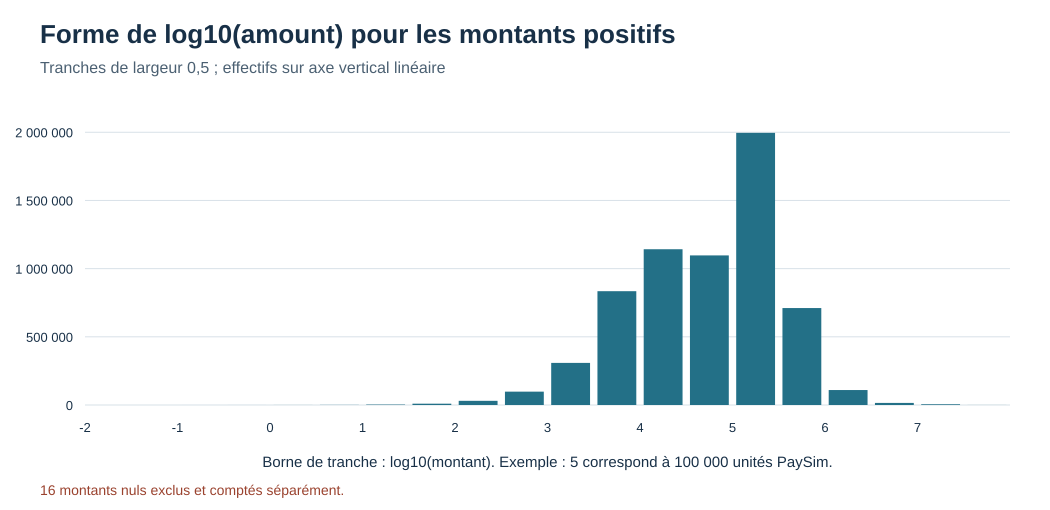

In [5]:
# Chaque tranche couvre 0,5 unité de log10(amount), soit un facteur 10**0,5.
log_bins = (
    frame.filter(pl.col("amount") > 0)
    .with_columns((pl.col("amount").log10() * 2).floor().cast(pl.Int32).alias("bin"))
    .group_by("bin").agg(pl.len().alias("count"))
    .sort("bin").collect()
)
assert sum(log_bins["count"].to_list()) == summary["total"] - summary["zeros"]
assert log_bins["bin"].to_list() == list(range(-4, 16))
log_stats = (
    frame.filter(pl.col("amount") > 0)
    .select(pl.col("amount").log10().mean().alias("mean"),
            pl.col("amount").log10().median().alias("median"),
            pl.col("amount").log10().skew().alias("skew"))
    .collect().row(0, named=True)
)
print("log10(amount), montants positifs :", log_stats)

width, height = 1050, 510
left, right, top, bottom = 85, 1010, 105, 405
counts = log_bins["count"].to_list()
bar_width = (right - left) / len(counts)
maximum = 2_200_000
parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">',
         '<rect width="100%" height="100%" fill="#ffffff"/>',
         svg_text(40, 43, "Forme de log10(amount) pour les montants positifs", size=26, weight="bold"),
         svg_text(40, 73, "Tranches de largeur 0,5 ; effectifs sur axe vertical linéaire", size=16, fill="#4b6072")]
for value in range(0, 2_000_001, 500_000):
    ypos = bottom - value / maximum * (bottom - top)
    parts += [f'<line x1="{left}" y1="{ypos}" x2="{right}" y2="{ypos}" stroke="#d8e1e8"/>',
              svg_text(left - 12, ypos + 5, format_int(value), size=13, anchor="end")]
for i, (bin_value, count) in enumerate(zip(log_bins["bin"].to_list(), counts)):
    center = left + (i + 0.5) * bar_width
    ypos = bottom - count / maximum * (bottom - top)
    parts.append(f'<rect x="{center - bar_width * 0.42}" y="{ypos}" width="{bar_width * 0.84}" height="{bottom - ypos}" fill="#237087"/>')
for log_value in range(-2, 9):
    i = 2 * (log_value + 2)
    if i < len(counts):
        xpos = left + i * bar_width
        parts.append(svg_text(xpos, 432, str(log_value), size=13, anchor="middle"))
parts += [svg_text((left + right) / 2, 467, "Borne de tranche : log10(montant). Exemple : 5 correspond à 100 000 unités PaySim.", size=15, anchor="middle"),
          svg_text(40, 495, "16 montants nuls exclus et comptés séparément.", size=14, fill="#9a422e"),
          '</svg>']
log_svg = save_svg("eda_log_montants.svg", "\n".join(parts))
show_svg(log_svg)


## Prochaine discussion

Les observations sur la forme du logarithme sont consignées dans `docs/EDA.md`. Nous examinerons ensuite les montants selon le label, sans sélectionner de variable ni de découpage temporel à ce stade.
